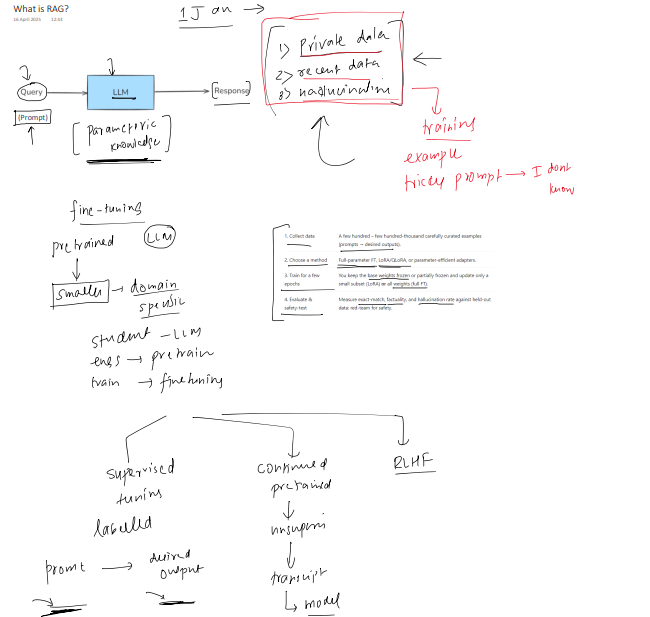

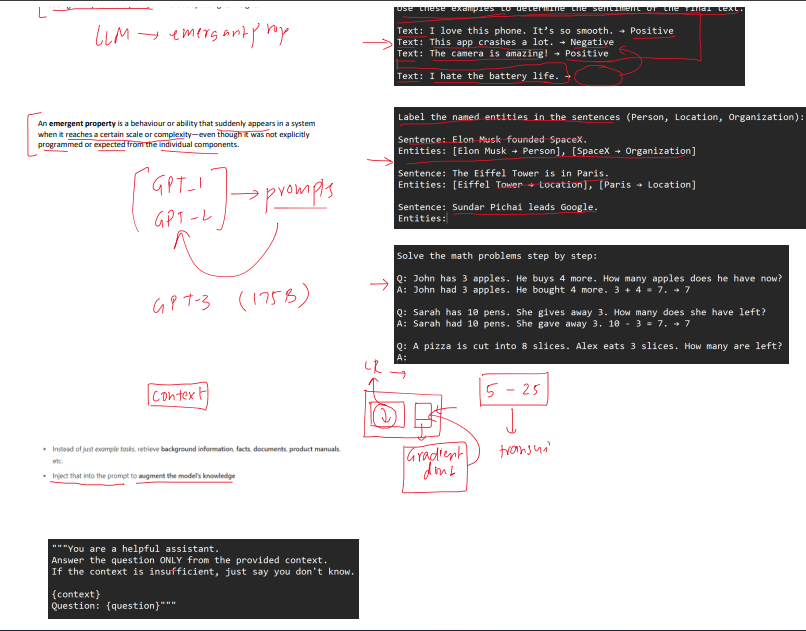

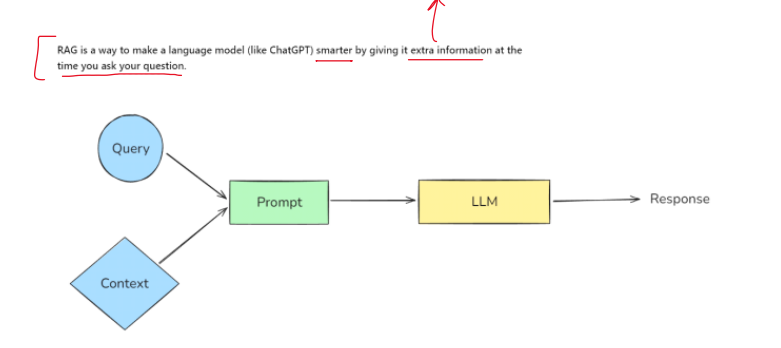

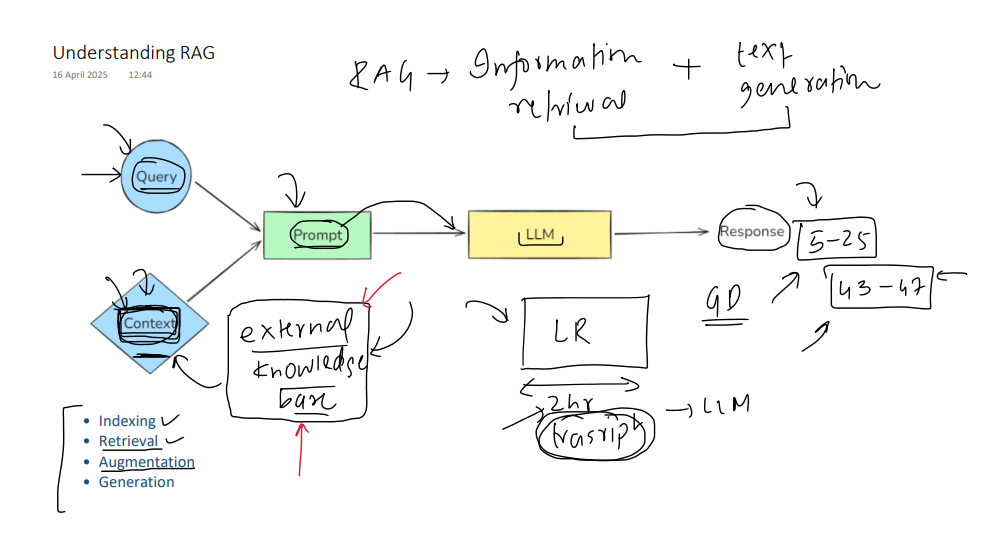

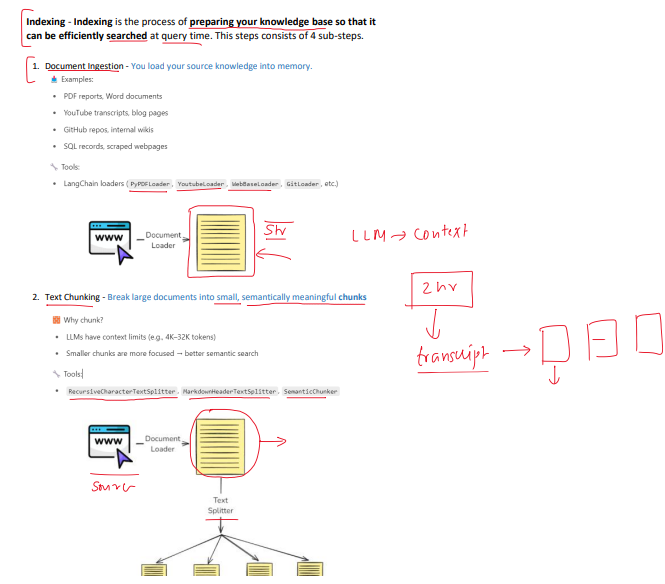

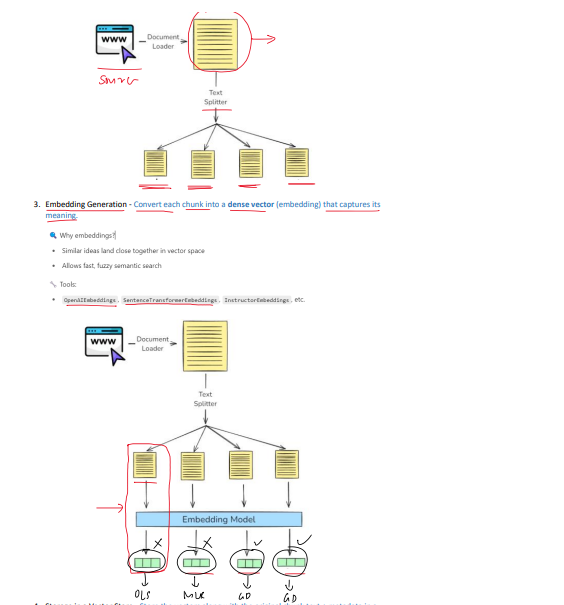

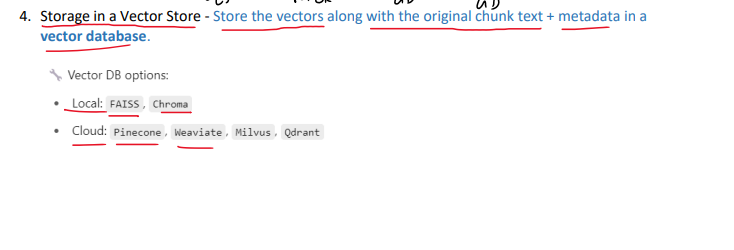

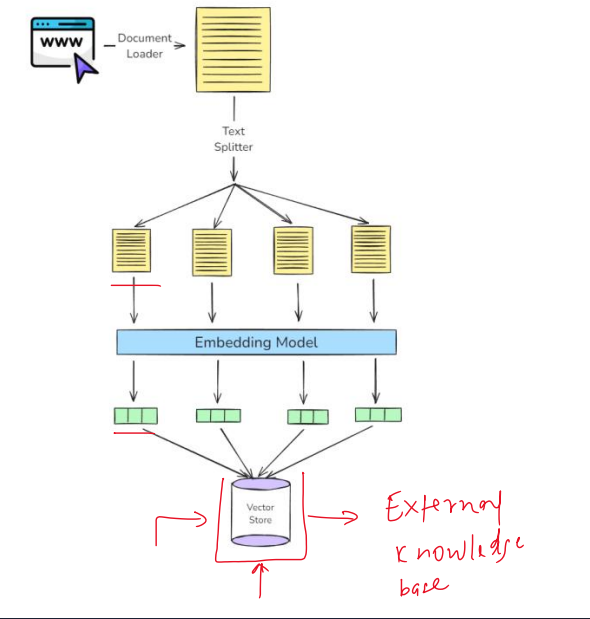

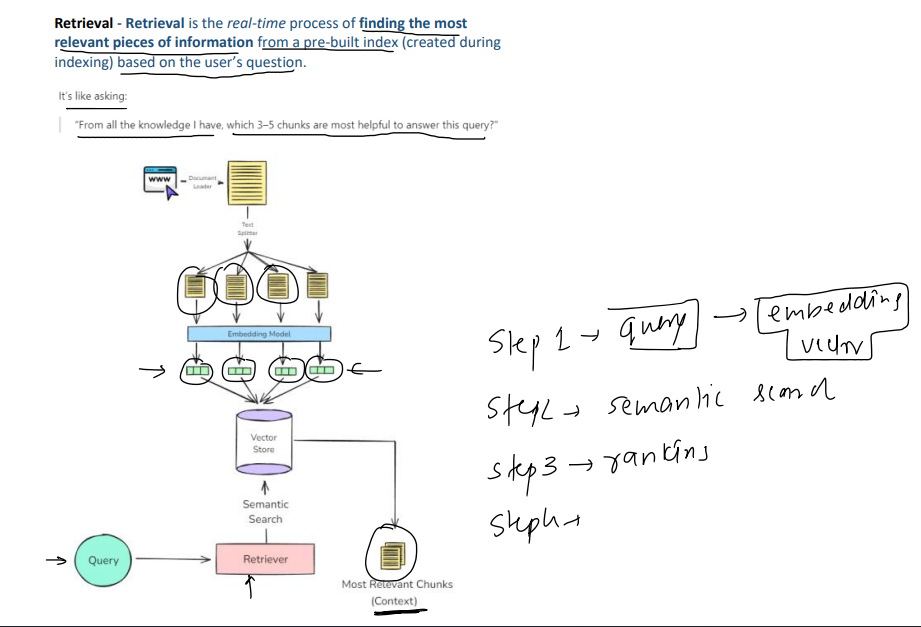

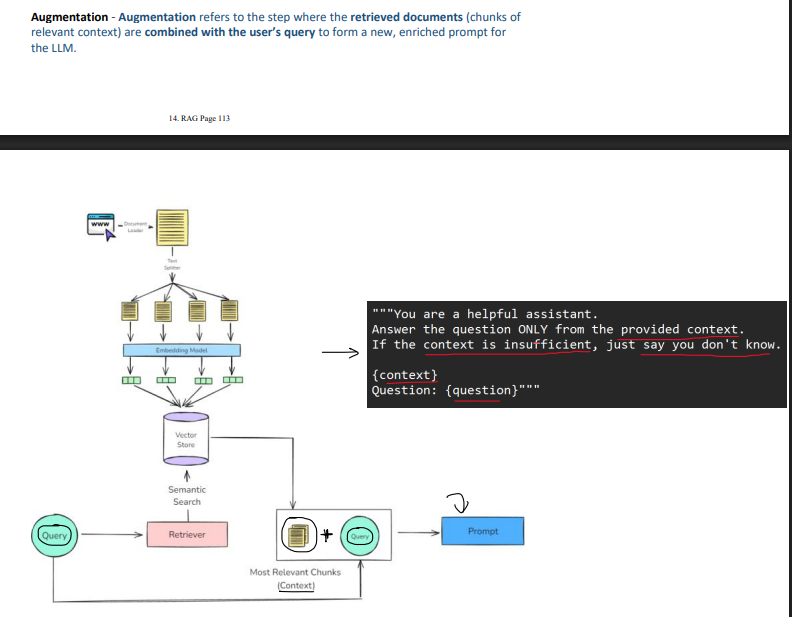

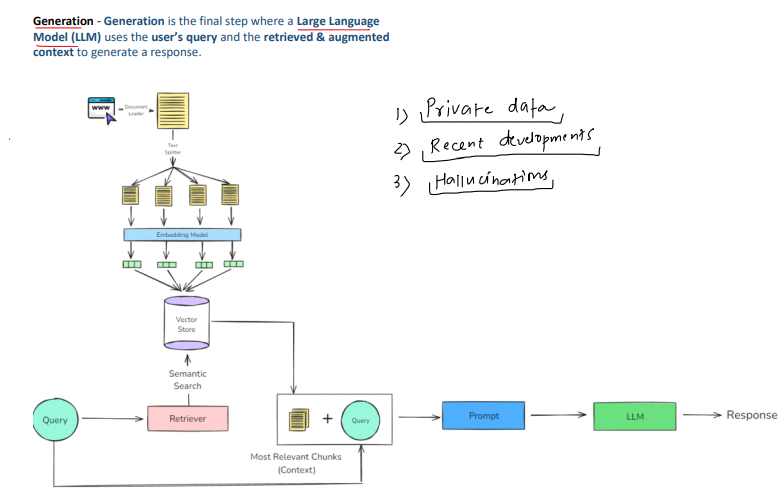

# YT CHATBOT


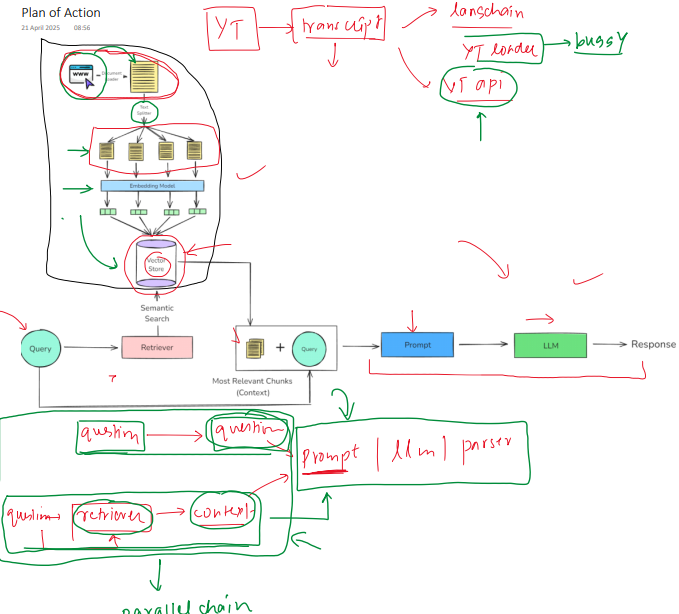

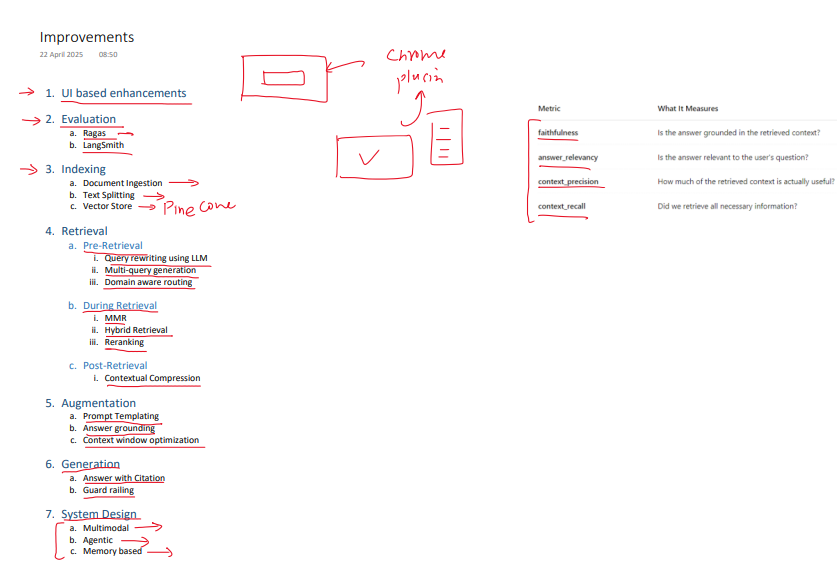

In [15]:
from youtube_transcript_api import YouTubeTranscriptApi, TranscriptsDisabled
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings, ChatGoogleGenerativeAI
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import PromptTemplate

### Step 1a - Indexing (Document Ingestion)

In [7]:
from youtube_transcript_api import (
    YouTubeTranscriptApi,
    TranscriptsDisabled,
    VideoUnavailable,
    IpBlocked,
)

video_id = "IHZwWFHWa-w"

try:
    fetched = YouTubeTranscriptApi().fetch(
        video_id,
        languages=["en"]
    )
    transcript = " ".join(snippet.text for snippet in fetched)
    print(transcript)

except TranscriptsDisabled:
    print("Captions are disabled for this video.")

except VideoUnavailable:
    print("The video is unavailable.")

except IpBlocked:
    print("YouTube has blocked requests from this IP. Try again later or use a permitted transcript source.")

Last video I laid out the structure of a neural network. I'll give a quick recap here so that it's fresh in our minds, and then I have two main goals for this video. The first is to introduce the idea of gradient descent, which underlies not only how neural networks learn, but how a lot of other machine learning works as well. Then after that we'll dig in a little more into how this particular network performs, and what those hidden layers of neurons end up looking for. As a reminder, our goal here is the classic example of handwritten digit recognition, the hello world of neural networks. These digits are rendered on a 28x28 pixel grid, each pixel with some grayscale value between 0 and 1. Those are what determine the activations of 784 neurons in the input layer of the network. And then the activation for each neuron in the following layers is based on a weighted sum of all the activations in the previous layer, plus some special number called a bias. Then you compose that sum with s

In [16]:
transcript_list

NameError: name 'transcript_list' is not defined

### Step 1b - Indexing (Text Splitting)

In [17]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.create_documents([transcript])
len(chunks)

25

In [18]:
chunks[4]

Document(metadata={}, page_content="is some indication of whether that neuron tends to be active or inactive. And to start things off, we're just going to initialize all of those weights and biases totally randomly. Needless to say, this network is going to perform pretty horribly on a given training example, since it's just doing something random. For example, you feed in this image of a 3, and the output layer just looks like a mess. So what you do is define a cost function, a way of telling the computer, no, bad computer, that output should have activations which are 0 for most neurons, but 1 for this neuron, what you gave me is utter trash. To say that a little more mathematically, you add up the squares of the differences between each of those trash output activations and the value you want them to have, and this is what we'll call the cost of a single training example. Notice this sum is small when the network confidently classifies the image correctly, but it's large when the ne

### Step 1c & 1d - Indexing (Embedding Generation and Storing in Vector Store)

In [19]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embeddings)

In [20]:
vector_store.index_to_docstore_id
## Faiss vector id and document id mapping

{0: 'b2f06d8d-45a6-40d0-93a3-18549e090fe1',
 1: 'e8e7dfbb-a374-4a8b-90ee-9dd1de785d89',
 2: '75e4d7d9-cc62-46f5-b7c8-c140143f8a99',
 3: '45c0f3b2-ee93-42a9-b30e-f2d226405e96',
 4: '66482d9d-e028-43f8-99be-e7cb39554243',
 5: 'ffdf5430-a454-4fa5-8249-9da84e783873',
 6: '84a52795-a0f7-4dd3-9c6e-46c3cc8ae7fd',
 7: '7568b32a-8b67-4d7a-9032-1c838c0b89be',
 8: '5039edae-5da0-45b5-a345-c844f0fca71f',
 9: '2d553492-851e-431d-9d23-7cba3718946c',
 10: 'c4bcf499-06d1-4f0b-bab5-0e9f1ae3d801',
 11: '57f503b6-c803-44fb-b519-540d69dee9f5',
 12: 'eb1e9192-cb53-4e2d-ae92-24fc4a961588',
 13: '8f926a7e-4f6f-4088-9f0d-d17fb3e3a5a4',
 14: '4f491760-5787-43f8-806c-11001f9cc629',
 15: 'ee7b5946-3c09-4520-9c5a-ad7b55fd298a',
 16: 'f8d34d37-dfa4-4935-997d-8b7c06609e26',
 17: '5bc3e637-036e-4090-86de-7f4d2980f9bb',
 18: 'fe14b81b-239f-429e-89f9-2ccb6e4ac77d',
 19: '2971a6f7-d61e-458f-9f72-d69f98b9c9c4',
 20: 'cc24b32e-0ba6-492e-887b-1bc5506f27cd',
 21: '53a5c374-8dd3-4232-9851-9a38f191dded',
 22: 'a67a1a61-a142-

In [22]:
vector_store.get_by_ids(['1208320c-3c20-4db2-8b1b-55602b946bfb'])

[Document(id='1208320c-3c20-4db2-8b1b-55602b946bfb', metadata={}, page_content="you fiddle around a little bit in the beginning, but then you kind of dropped very fast to get to that accuracy level, and so in some sense it was easier to find that local maxima. And so what was also interesting about that is it brings into light another paper from actually a couple of years ago, which has a lot more simplifications about the network layers, but one of the results was saying how if you look at the optimization landscape, the local minima that these networks tend to learn are actually of equal quality, so in some sense if your dataset is structured, you should be able to find that much more easily. My thanks, as always, to those of you supporting on Patreon. I've said before just what a game changer Patreon is, but these videos really would not be possible without you. I also want to give a special thanks to the VC firm Amplify Partners and their support of these initial videos in the seri

# Step 2 - Retrieval

In [23]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
retriever

VectorStoreRetriever(tags=['FAISS', 'GoogleGenerativeAIEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x0000023F155078C0>, search_kwargs={'k': 4})

In [24]:
retriever.invoke("what is cost function")


[Document(id='ffdf5430-a454-4fa5-8249-9da84e783873', metadata={}, page_content="what we'll call the cost of a single training example. Notice this sum is small when the network confidently classifies the image correctly, but it's large when the network seems like it doesn't know what it's doing. So then what you do is consider the average cost over all of the tens of thousands of training examples at your disposal. This average cost is our measure for how lousy the network is, and how bad the computer should feel. And that's a complicated thing. Remember how the network itself was basically a function, one that takes in 784 numbers as inputs, the pixel values, and spits out 10 numbers as its output, and in a sense it's parameterized by all these weights and biases? Well the cost function is a layer of complexity on top of that. It takes as its input those 13,000 or so weights and biases, and spits out a single number describing how bad those weights and biases are, and the way it's def

# Step 3 - Augmentation

In [25]:
llm = ChatGoogleGenerativeAI(model= 'gemini-3.6-flash', temperature=0.2)

In [26]:
prompt = PromptTemplate(
    template="""
     You are a helpful assistant.
      Answer ONLY from the provided transcript context.
      If the context is insufficient, just say you don't know.

      {context}
      Question: {question}
    """,
    input_variables = ['context', 'question']
)

In [27]:
question          = "is the author of the video discuss about the interview of lisha li "
retrieved_docs    = retriever.invoke(question)
retrieved_docs

[Document(id='a67a1a61-a142-476f-9bf2-aee21ae58253', metadata={}, page_content="with Leisha Lee. You might remember her from the last video, she did her PhD work in deep learning. In this little snippet she talks about two recent papers that really dig into how some of the more modern image recognition networks are actually learning. Just to set up where we were in the conversation, the first paper took one of these particularly deep neural networks that's really good at image recognition, and instead of training it on a properly labeled dataset, shuffled all the labels around before training. Obviously the testing accuracy here was going to be no better than random, since everything's just randomly labeled. But it was still able to achieve the same training accuracy as you would on a properly labeled dataset. Basically, the millions of weights for this particular network were enough for it to just memorize the random data, which raises the question for whether minimizing this cost fun

In [28]:
context_text = "\n\n".join(doc.page_content for doc in retrieved_docs)
context_text

"with Leisha Lee. You might remember her from the last video, she did her PhD work in deep learning. In this little snippet she talks about two recent papers that really dig into how some of the more modern image recognition networks are actually learning. Just to set up where we were in the conversation, the first paper took one of these particularly deep neural networks that's really good at image recognition, and instead of training it on a properly labeled dataset, shuffled all the labels around before training. Obviously the testing accuracy here was going to be no better than random, since everything's just randomly labeled. But it was still able to achieve the same training accuracy as you would on a properly labeled dataset. Basically, the millions of weights for this particular network were enough for it to just memorize the random data, which raises the question for whether minimizing this cost function actually corresponds to any sort of structure in the image, or is it just

In [29]:
final_prompt = prompt.invoke({"context": context_text, "question": question})
final_prompt

StringPromptValue(text="\n     You are a helpful assistant.\n      Answer ONLY from the provided transcript context.\n      If the context is insufficient, just say you don't know.\n\n      with Leisha Lee. You might remember her from the last video, she did her PhD work in deep learning. In this little snippet she talks about two recent papers that really dig into how some of the more modern image recognition networks are actually learning. Just to set up where we were in the conversation, the first paper took one of these particularly deep neural networks that's really good at image recognition, and instead of training it on a properly labeled dataset, shuffled all the labels around before training. Obviously the testing accuracy here was going to be no better than random, since everything's just randomly labeled. But it was still able to achieve the same training accuracy as you would on a properly labeled dataset. Basically, the millions of weights for this particular network were 

# step 4 Generation


In [30]:
answer = llm.invoke(final_prompt)
print(answer.content)


c:\Users\Admin\Desktop\gen1\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


[{'type': 'text', 'text': 'Yes, the author mentions discussing a snippet of an interview they had with Leisha Lee, where she talks about recent papers regarding how modern image recognition networks learn.', 'extras': {'signature': 'EvILCu8LAWkUfRPUb3DWHn5uXlzDNMb45N3onzLzgAPeZGJrFtiu7BeuZnVZBEMANkMpBU7sxqolHTH9CukaWVkZ5QAb/wuuN9HPTwiuhmuYU2M0zXYdRp/eKPZjYF9Fosu6B3mRuy4yNKGhwqMO5BG8ic+zqCGGqtdoizICvvT4VCDdA4tcFukkNQCNXYxBWQd4TN7RMBKbDGXxvXzU0ERhfHu+qB4bXjYOVkbAEMYutxkd/TW8yxAfcLjj+DSS/SKOAh+27iGNUevHK/Z0ub41wFl7wof5BUhOwHIDpSvmGW5OUIEZix0ZHOZK3h68VQ2Zm+W/TrvLadJSb84FkjzvOfc1YptCU6no6xZsldLhu1eu/bzpqkO06SbRdsO3mVqa+ZXx999i1Yopj8YiU+J9uF/lR3wBFXxNWZuQ85BekCI7BaiDemtWeqsrr1YJHEiwFJGfFLzp/5MH8/feAWHnBaL2TeClISnBfnPlvEskAoIz7MzSxuXUgcISK4sVUIbO3y3tp+zc8n1M16x2EIYWmCGnIg3as6LNBoA9OYp/VfNSAXa6Lwr9nLsvb7GZTzxMLu2+wJeowM1VfFuoA7/0DkXABOAo386G0acOgeYfV+MJ1gv2v6LqAwOkxLFYxvqKK7GjaRBqOa4H3cVIV+FG7ZSpUV8xSBfuj1lFthIJdWWY/+7BzujLuS7R9Q5/f74Hap0vTKlcrPuqn5pd5epJSqRDwL1BohjqK4Jck0dRSe+0EfLkusGzJ3MWkP8

# Building the chain

In [31]:
from langchain_core.runnables import RunnableParallel, RunnablePassthrough, RunnableLambda
from langchain_core.output_parsers import StrOutputParser

In [32]:
def format_docs(retrieved_docs):
  context_text = "\n\n".join(doc.page_content for doc in retrieved_docs)
  return context_text

In [33]:
parallel_chain = RunnableParallel({
    'context' : retriever | RunnableLambda(format_docs),
    'question':RunnablePassthrough()
})

In [34]:
parallel_chain.invoke('what is cost fn')

{'context': "what we'll call the cost of a single training example. Notice this sum is small when the network confidently classifies the image correctly, but it's large when the network seems like it doesn't know what it's doing. So then what you do is consider the average cost over all of the tens of thousands of training examples at your disposal. This average cost is our measure for how lousy the network is, and how bad the computer should feel. And that's a complicated thing. Remember how the network itself was basically a function, one that takes in 784 numbers as inputs, the pixel values, and spits out 10 numbers as its output, and in a sense it's parameterized by all these weights and biases? Well the cost function is a layer of complexity on top of that. It takes as its input those 13,000 or so weights and biases, and spits out a single number describing how bad those weights and biases are, and the way it's defined depends on the network's behavior over all the tens of thousan

In [35]:
parser = StrOutputParser()
main_chain = parallel_chain | prompt | llm | parser
main_chain.invoke('can u summarize the video')

c:\Users\Admin\Desktop\gen1\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


"Based on the provided context, the video covers the following main topics:\n\n* **Discussion on Image Recognition Papers:** Leisha Lee discusses two papers about how deep learning networks learn. One paper showed that a network could memorize a randomly labeled dataset (achieving high training accuracy), raising questions about cost functions. The second paper showed that local minima in optimization landscapes are of equal quality, making structured datasets easier for networks to learn.\n* **Acknowledgements:** A brief thanks to Patreon supporters and Amplify Partners.\n* **Neural Network Setup:** A recap of a neural network designed for handwritten digit recognition, which uses a 28x28 pixel grid (784 input neurons) and produces 10 outputs using weighted sums and biases.\n* **Gradient Descent and Cost Function:** An explanation of the cost function, which evaluates the network's performance across 13,000 weights and biases, and how the gradient of the cost function guides gradient 